# Olist Fulfillment Pulse — quick EDA

This notebook examines the compact order-level file used by the Streamlit app. Each row is one **delivered** Olist order; orders still in progress are excluded because their delivery time and on-time status are not defined.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv('olist_order_health.csv', parse_dates=['purchase_date'])
orders.shape


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/gaoe/.cache/fontconfig
	/Users/gaoe/.fontconfig


Matplotlib is building the font cache; this may take a moment.


(96476, 13)

## Structure and data quality

In [2]:
display(orders.dtypes.to_frame('dtype'))
display(orders.isna().sum().sort_values(ascending=False).to_frame('missing values'))
print('Purchase period:', orders.purchase_date.min().date(), 'to', orders.purchase_date.max().date())
print('On-time rate:', f"{1 - orders.late_delivery.mean():.1%}")
print('Average delivery time:', f"{orders.delivery_days.mean():.1f} days")

,dtype
order_id,object
purchase_date,datetime64[ns]
purchase_month,object
order_status,object
customer_state,object
primary_category,object
merchandise_value_brl,float64
freight_value_brl,float64
review_score,float64
was_delivered,bool


,missing values
review_score,646
order_id,0
purchase_date,0
purchase_month,0
order_status,0
customer_state,0
primary_category,0
merchandise_value_brl,0
freight_value_brl,0
was_delivered,0


Purchase period: 2016-09-15 to 2018-08-29
On-time rate: 91.9%
Average delivery time: 12.6 days


`review_score` is missing for a small number of orders because no score was recorded. The app labels missing product categories `Unknown` rather than silently dropping them.

## Delivery reliability over time

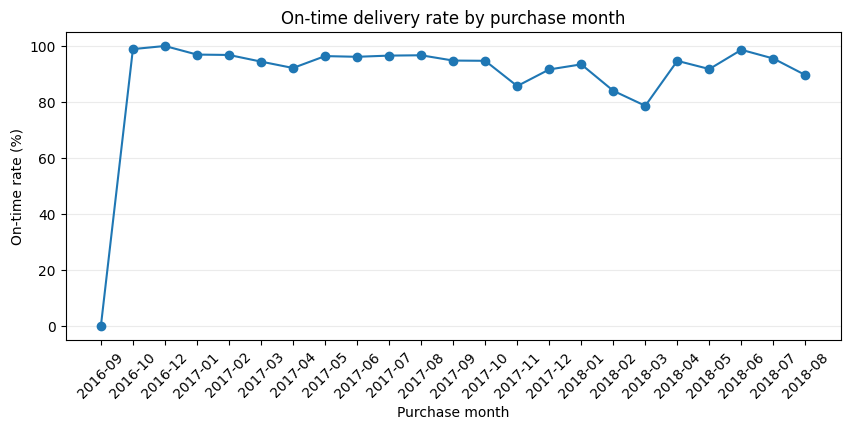

,purchase_month,orders,late_rate
0,2016-09,1,1.000000
17,2018-03,7003,0.213623
16,2018-02,6556,0.160006
13,2017-11,7288,0.143112
22,2018-08,6351,0.103921
14,2017-12,5513,0.083802
19,2018-05,6749,0.082383
6,2017-04,2303,0.078593


In [3]:
monthly = orders.groupby('purchase_month', as_index=False).agg(
    orders=('order_id', 'size'), late_rate=('late_delivery', 'mean')
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.purchase_month, (1-monthly.late_rate)*100, marker='o')
ax.set(title='On-time delivery rate by purchase month', ylabel='On-time rate (%)', xlabel='Purchase month')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=.25)
plt.show()
monthly.sort_values('late_rate', ascending=False).head(8)

## State differences

In [4]:
state_risk = orders.groupby('customer_state', as_index=False).agg(
    delivered_orders=('order_id', 'size'),
    late_rate=('late_delivery', 'mean'),
    average_review=('review_score', 'mean')
).query('delivered_orders >= 50').sort_values('late_rate', ascending=False)
state_risk.head(12)

,customer_state,delivered_orders,late_rate,average_review
1,AL,397,0.239295,3.852792
9,MA,717,0.196653,3.833567
16,PI,476,0.159664,3.993631
5,CE,1279,0.153245,3.941870
24,SE,335,0.152239,3.907186
4,BA,3256,0.140356,3.930009
18,RJ,12353,0.134704,3.964412
26,TO,274,0.127737,4.153846
13,PA,946,0.123679,3.909968
7,ES,1995,0.122306,4.079736


**Dashboard implication.** The EDA supports a weekly operations dashboard centered on on-time delivery, delivery time, the monthly trend, and a state–category priority list. We do not include revenue or payment breakdowns because they do not change the operations director's fulfillment decision. State differences are priorities to investigate, not proof of causality: this snapshot has no carrier or root-cause field.